# UCS420: Cognitive Computing
## Assignment 10 — Heart Health Information Assistant
*(Roll number 1024160140 is even, so the assigned topic is the Heart Health Information Assistant.)*

**Name:** Prashant Narayan Verma  
**Roll No.:** 1024160140

A Python healthcare cognitive assistant that **understands** a query (NLP), **identifies the intent** (TF-IDF + Logistic Regression),
**reasons** over rules and a concept graph, **retrieves** information from a knowledge base and **generates** a response.

> ⚠️ This assistant gives general educational information only. It is not a diagnostic tool and cannot replace a doctor.
> In a possible emergency (for example severe chest pain) it tells the user to call emergency services at once.

**Pipeline:** query → rules (emergency, small-talk, unsupported) → preprocessing → intent classifier → rules (low confidence, medication safety, BP reading) → knowledge retrieval → concept reasoning → response

In [1]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
warnings.filterwarnings("ignore")

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print("Setup complete")

Setup complete


## 1. Labelled corpus (Requirement 1)
175 queries, 25 for each of **7 intent categories**: `symptoms`, `risk_factors`, `prevention`, `diagnosis_tests`, `monitoring_numbers`, `treatment`, `emergency`.

In [2]:
corpus = {
    "symptoms": [
        "what are the symptoms of a heart attack",
        "how does angina feel",
        "what are the signs of heart failure",
        "why does my heart flutter or skip beats",
        "is shortness of breath a sign of heart disease",
        "what are the warning signs of heart problems in women",
        "swollen ankles and feeling tired could it be my heart",
        "what does a heart palpitation feel like",
        "what does chest pain from the heart feel like",
        "can heart disease cause dizziness and fainting",
        "early signs of a heart problem",
        "what are the symptoms of a silent heart attack",
        "is pain in my left arm a heart symptom",
        "how do I know if my breathlessness is due to the heart",
        "what are the common symptoms of coronary artery disease",
        "what are the symptoms of heart disease in men",
        "does heart disease cause tiredness all the time",
        "why does my chest feel tight when I walk fast",
        "signs of a weak heart",
        "can a heart problem cause pain in the back or jaw",
        "what does an irregular heartbeat feel like",
        "why do I get breathless climbing stairs",
        "how does a mini heart attack feel",
        "what are the symptoms of a blocked artery",
        "why are my feet swollen is it a heart problem",
    ],
    "risk_factors": [
        "what causes heart disease",
        "does high blood pressure increase the risk of a heart attack",
        "is diabetes a risk factor for heart disease",
        "does smoking damage the heart",
        "am I at higher risk if my father had an early heart attack",
        "how does obesity affect heart health",
        "what are the risk factors for coronary artery disease",
        "can stress cause heart problems",
        "can smoking cause a heart attack",
        "why is high cholesterol bad for the heart",
        "does drinking alcohol increase heart risk",
        "are South Asians more likely to get heart disease",
        "does age affect the chance of heart disease",
        "is a family history of heart disease dangerous",
        "what makes arteries get blocked",
        "what increases the chance of a heart attack",
        "why are diabetics more prone to heart disease",
        "does being overweight harm the heart",
        "is high blood pressure dangerous for the heart",
        "does eating junk food lead to heart disease",
        "who is most at risk of heart disease",
        "does lack of exercise cause heart problems",
        "is heart disease hereditary",
        "how does cholesterol build up in arteries",
        "do young people get heart attacks and why",
    ],
    "prevention": [
        "how can I keep my heart healthy",
        "which foods are good for the heart",
        "how much exercise is needed for heart health",
        "how do I reduce my chance of getting heart disease",
        "should I cut down salt to protect my heart",
        "how does quitting smoking help my heart",
        "what lifestyle changes prevent a heart attack",
        "can walking every day improve heart health",
        "what should I eat to avoid heart problems",
        "is cardio good for the heart",
        "how much salt is safe for a healthy heart",
        "how can I lower my risk of a heart attack naturally",
        "does sleep matter for heart health",
        "tips for a healthy heart",
        "is yoga or meditation good for the heart",
        "how can I prevent heart disease",
        "what is a heart healthy diet",
        "how can I strengthen my heart",
        "is it okay to eat eggs and ghee for a healthy heart",
        "how can I lower my cholesterol with food",
        "what habits protect against heart attacks",
        "should I take up jogging for my heart",
        "how to lead a heart healthy lifestyle",
        "how does reducing stress help the heart",
        "what is the best exercise for the heart",
    ],
    "diagnosis_tests": [
        "what is an ECG test",
        "how is heart disease diagnosed",
        "what does an echocardiogram show",
        "what is a treadmill stress test",
        "which blood tests check the heart",
        "what is coronary angiography",
        "do I need a lipid profile test",
        "how is a heart attack confirmed in the hospital",
        "how does a doctor check if my heart is working properly",
        "what is a TMT test",
        "what is a 2D echo",
        "what is a troponin test",
        "which tests are done for chest pain",
        "how do doctors find blocked arteries",
        "what is a holter monitor test",
        "how do doctors diagnose a heart attack",
        "what test shows a heart blockage",
        "what is a CT calcium score",
        "what is the test for heart rhythm problems",
        "what does an ejection fraction test tell",
        "is an ECG enough to detect heart disease",
        "how is heart failure diagnosed",
        "what happens during an angiogram",
        "which scan checks the heart arteries",
        "what is a cardiac MRI used for",
    ],
    "monitoring_numbers": [
        "what is a normal blood pressure reading",
        "how do I measure blood pressure at home",
        "what cholesterol level is considered high",
        "what is a good LDL number",
        "is 140/90 blood pressure high",
        "what is the ideal triglyceride level",
        "how often should I check my blood pressure",
        "what is the difference between HDL and LDL cholesterol",
        "what is the normal range for blood pressure",
        "what should my cholesterol numbers be",
        "what is stage 2 hypertension",
        "how high is too high for LDL",
        "what does the top number in blood pressure mean",
        "what is a healthy HDL level",
        "how do I read my lipid report numbers",
        "what is a healthy blood pressure for an adult",
        "what is considered low blood pressure",
        "what does 120/80 mean",
        "what is the target LDL for heart patients",
        "what is the normal level of total cholesterol",
        "how do I know if my blood pressure is too high",
        "what are normal triglyceride numbers",
        "how often should I test my cholesterol",
        "what is the difference between systolic and diastolic pressure",
        "is 130/85 a normal reading",
    ],
    "treatment": [
        "what medicines are used for heart disease",
        "what is angioplasty",
        "how does bypass surgery work",
        "what does a statin do",
        "what is cardiac rehabilitation",
        "what is a pacemaker and when is it needed",
        "how do beta blockers help the heart",
        "can I stop my heart medicine if I feel better",
        "how are heart blockages treated",
        "what is a stent",
        "what is the difference between angioplasty and bypass",
        "which tablets are given after a heart attack",
        "how does an ICD or defibrillator work",
        "what is the role of aspirin in heart disease",
        "how do ACE inhibitors work",
        "how is heart failure treated",
        "what drugs lower cholesterol",
        "what is recovery from bypass surgery like",
        "what are stents made of and how long do they last",
        "what is a heart transplant",
        "do I need surgery for a blocked artery",
        "what is the treatment for angina",
        "how do blood thinners help heart patients",
        "what does a cardiologist prescribe for high blood pressure",
        "what is a valve replacement",
    ],
    "emergency": [
        "I am having severe chest pain right now",
        "I think I am having a heart attack",
        "my father collapsed and is not responding",
        "crushing chest pain spreading to my left arm and jaw",
        "someone is unconscious and not breathing normally",
        "sudden severe breathlessness with chest tightness",
        "what should I do if someone is having a heart attack",
        "should I call an ambulance for chest pain",
        "my chest feels like it is being squeezed and I am sweating a lot",
        "help my husband is clutching his chest and cannot speak",
        "what to do when someone faints and is not breathing",
        "is it a heart attack if my arm and jaw hurt suddenly",
        "call an ambulance my mother has severe chest pain",
        "sudden chest pain with cold sweat what should I do",
        "how do I give CPR to someone who has collapsed",
        "my friend has collapsed and has no pulse",
        "I have crushing pain in my chest and cannot breathe",
        "what should I do if I am alone and having chest pain",
        "someone near me is clutching their chest and sweating heavily",
        "how do I use an AED on a person who has collapsed",
        "my grandfather suddenly fell down and is not breathing",
        "my chest pain is getting worse and spreading to my shoulder",
        "when should I call 112 for chest pain",
        "first aid for a heart attack",
        "my husband has severe chest pain and is vomiting",
    ],
}

df = pd.DataFrame([(q, intent) for intent, qs in corpus.items() for q in qs], columns=["query", "intent"])
print("Total queries:", len(df), "| intents:", df["intent"].nunique())
print(df["intent"].value_counts().to_string())
df.sample(8, random_state=1).reset_index(drop=True)

Total queries: 175 | intents: 7
intent
symptoms              25
risk_factors          25
prevention            25
diagnosis_tests       25
monitoring_numbers    25
treatment             25
emergency             25


,query,intent
0,what is the test for heart rhythm problems,diagnosis_tests
1,how do I read my lipid report numbers,monitoring_numbers
2,can a heart problem cause pain in the back or jaw,symptoms
3,how can I lower my cholesterol with food,prevention
4,how do I reduce my chance of getting heart disease,prevention
5,what is the difference between angioplasty and bypass,treatment
6,what is angioplasty,treatment
7,what are the common symptoms of coronary artery disease,symptoms


## 2. Hierarchical taxonomy (Requirement 2)
5 major categories, each with 2–3 subcategories. Every intent is attached to one subcategory.

In [3]:
taxonomy = {
    "Symptoms & Warning Signs": {
        "Heart attack & angina signs": "symptoms",
        "Heart failure & rhythm symptoms": "symptoms",
    },
    "Risk Factors & Prevention": {
        "Medical & inherited risk factors": "risk_factors",
        "Healthy-lifestyle prevention": "prevention",
    },
    "Diagnosis & Monitoring": {
        "Heart tests & imaging": "diagnosis_tests",
        "Blood pressure & cholesterol numbers": "monitoring_numbers",
    },
    "Treatment & Care": {
        "Medicines": "treatment",
        "Procedures & cardiac rehabilitation": "treatment",
    },
    "Emergency Care": {
        "Recognising an emergency": "emergency",
        "First aid while waiting for help": "emergency",
    },
}

for major, subs in taxonomy.items():
    print(major)
    for sub, intent in subs.items():
        print(f"   |- {sub}   [intent: {intent}]")
print("\nMajor categories:", len(taxonomy), "| subcategories:", sum(len(s) for s in taxonomy.values()))

Symptoms & Warning Signs
   |- Heart attack & angina signs   [intent: symptoms]
   |- Heart failure & rhythm symptoms   [intent: symptoms]
Risk Factors & Prevention
   |- Medical & inherited risk factors   [intent: risk_factors]
   |- Healthy-lifestyle prevention   [intent: prevention]
Diagnosis & Monitoring
   |- Heart tests & imaging   [intent: diagnosis_tests]
   |- Blood pressure & cholesterol numbers   [intent: monitoring_numbers]
Treatment & Care
   |- Medicines   [intent: treatment]
   |- Procedures & cardiac rehabilitation   [intent: treatment]
Emergency Care
   |- Recognising an emergency   [intent: emergency]
   |- First aid while waiting for help   [intent: emergency]

Major categories: 5 | subcategories: 10


## 3. Domain concepts and relationships (Requirement 3)
15 concepts and 17 relationships form a small knowledge graph. The assistant later uses it for *reasoning* (it adds related facts for any concept found in the query).

In [4]:
concepts = ["Smoking", "High Cholesterol", "Hypertension", "Diabetes", "Obesity", "Atherosclerosis",
            "Coronary Artery Disease", "Angina", "Heart Attack", "Heart Failure", "Arrhythmia",
            "ECG", "Statins", "Exercise", "Healthy Diet"]

relationships = [
    ("Smoking", "increases risk of", "Atherosclerosis"),
    ("High Cholesterol", "causes", "Atherosclerosis"),
    ("Atherosclerosis", "leads to", "Coronary Artery Disease"),
    ("Coronary Artery Disease", "causes", "Angina"),
    ("Coronary Artery Disease", "can lead to", "Heart Attack"),
    ("Hypertension", "increases risk of", "Heart Attack"),
    ("Hypertension", "increases risk of", "Heart Failure"),
    ("Diabetes", "increases risk of", "Coronary Artery Disease"),
    ("Obesity", "increases risk of", "Hypertension"),
    ("Heart Attack", "can cause", "Heart Failure"),
    ("ECG", "helps detect", "Arrhythmia"),
    ("ECG", "helps diagnose", "Heart Attack"),
    ("Statins", "lower", "High Cholesterol"),
    ("Exercise", "helps lower", "Hypertension"),
    ("Exercise", "helps prevent", "Coronary Artery Disease"),
    ("Healthy Diet", "helps lower", "High Cholesterol"),
    ("Obesity", "increases risk of", "Diabetes"),
]

rel_df = pd.DataFrame(relationships, columns=["concept", "relation", "related concept"])
print("Concepts:", len(concepts), "| relationships:", len(relationships))
rel_df

Concepts: 15 | relationships: 17


,concept,relation,related concept
0,Smoking,increases risk of,Atherosclerosis
1,High Cholesterol,causes,Atherosclerosis
2,Atherosclerosis,leads to,Coronary Artery Disease
3,Coronary Artery Disease,causes,Angina
4,Coronary Artery Disease,can lead to,Heart Attack
5,Hypertension,increases risk of,Heart Attack
6,Hypertension,increases risk of,Heart Failure
7,Diabetes,increases risk of,Coronary Artery Disease
8,Obesity,increases risk of,Hypertension
9,Heart Attack,can cause,Heart Failure


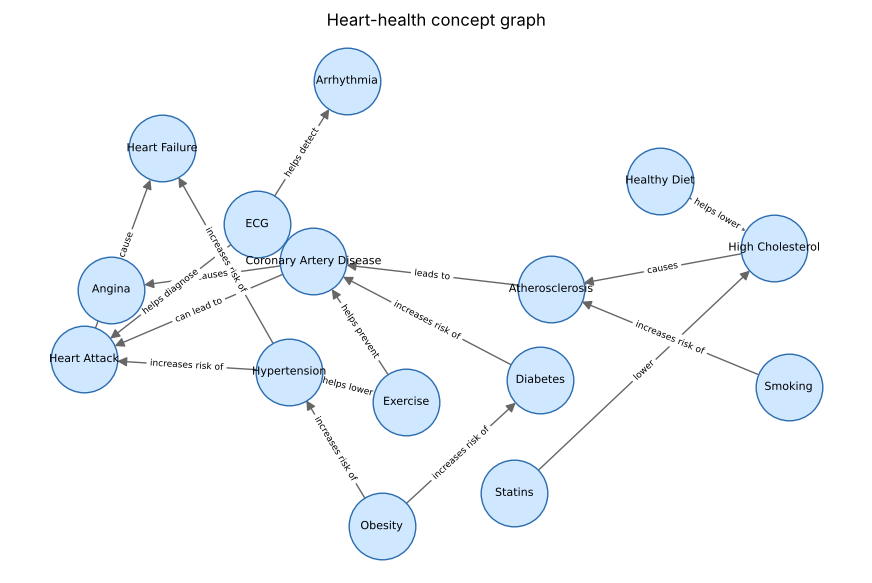

In [5]:
import networkx as nx
G = nx.DiGraph()
G.add_nodes_from(concepts)
for a, r, b in relationships:
    G.add_edge(a, b, label=r)

plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, seed=4, k=1.1)
nx.draw_networkx_nodes(G, pos, node_color="#cfe8ff", node_size=2300, edgecolors="#2b6cb0")
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=14, edge_color="#666", node_size=2300)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=6.5)
plt.title("Heart-health concept graph")
plt.axis("off")
plt.show()

## 4. NLP preprocessing (Requirement 4)
Lowercase conversion → tokenization → stopword removal → lemmatization.  
`no` and `not` are kept (they change meaning) and numbers are mapped to a single token so that "140/90" and "150/95" look alike to the classifier.

In [6]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()
STOP = (set(stopwords.words("english")) - {"no", "not"}) | {"please", "tell", "want"}

def lowercase(text):
    return text.lower()

def tokenize(text):
    toks = word_tokenize(text)
    toks = [t for t in toks if re.search(r"[a-z0-9]", t)]          # drop pure punctuation
    return ["numval" if re.fullmatch(r"\d+(?:[/.]\d+)?", t) else t for t in toks]

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP]

def lemmatize(tokens):
    return [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in tokens]

def preprocess(text):
    """Full pipeline: returns the list of cleaned lemma tokens."""
    return lemmatize(remove_stopwords(tokenize(lowercase(text))))

# Show every step for a few queries
demo = ["What are the SYMPTOMS of a heart attack?",
        "Is 140/90 blood pressure high?",
        "My father collapsed and is not breathing!"]
rows = []
for q in demo:
    lo = lowercase(q); tk = tokenize(lo); sw = remove_stopwords(tk); lm = lemmatize(sw)
    rows.append([q, lo, tk, sw, lm])
pd.DataFrame(rows, columns=["raw", "lowercase", "tokens", "no stopwords", "lemmas"])

,raw,lowercase,tokens,no stopwords,lemmas
0,What are the SYMPTOMS of a heart attack?,what are the symptoms of a heart attack?,"[what, are, the, symptoms, of, a, heart, attack]","[symptoms, heart, attack]","[symptom, heart, attack]"
1,Is 140/90 blood pressure high?,is 140/90 blood pressure high?,"[is, numval, blood, pressure, high]","[numval, blood, pressure, high]","[numval, blood, pressure, high]"
2,My father collapsed and is not breathing!,my father collapsed and is not breathing!,"[my, father, collapsed, and, is, not, breathing]","[father, collapsed, not, breathing]","[father, collapse, not, breathe]"


## 5. TF-IDF features and intent classifier (Requirement 5)
Two TF-IDF blocks feed the classifier: word unigrams + bigrams over the preprocessed tokens, and character 3-5-grams (which cope with word-form variants such as *smoker / smoking*). Naive Bayes, Logistic Regression and a linear SVM are compared with stratified cross-validation; **Logistic Regression** is used in the assistant because it gives class probabilities, which the low-confidence rule needs.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

from sklearn.pipeline import FeatureUnion

def make_word_vectorizer():
    """Word uni+bigram TF-IDF over the preprocessed (lowercased, stopword-free, lemmatized) tokens."""
    return TfidfVectorizer(tokenizer=preprocess, lowercase=False, token_pattern=None,
                           ngram_range=(1, 2), sublinear_tf=True)

def make_vectorizer():
    """Classifier features: the word-level TF-IDF plus character 3-5-gram TF-IDF (robust to spelling/word-form variants)."""
    return FeatureUnion([("word", make_word_vectorizer()),
                         ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True))])

models = {
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=20, max_iter=2000),
    "Linear SVM": LinearSVC(C=1.0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", make_vectorizer()), ("clf", clf)])
    scores = cross_val_score(pipe, df["query"], df["intent"], cv=cv, scoring="accuracy")
    rows.append([name, scores.mean().round(3), scores.std().round(3)])
pd.DataFrame(rows, columns=["model", "mean CV accuracy", "std"])

,model,mean CV accuracy,std
0,Naive Bayes,0.726,0.076
1,Logistic Regression,0.766,0.033
2,Linear SVM,0.760,0.039


## 6. Evaluation (Requirement 6)
70 % / 30 % stratified split. Accuracy, per-class precision / recall / F1 and the confusion matrix are reported.
A second, harder test uses 14 **differently worded** queries that are *not* in the corpus.

Train size: 122 | Test size: 53
Accuracy         : 0.736
Macro precision  : 0.767
Macro recall     : 0.742
Macro F1-score   : 0.715

                    precision    recall  f1-score   support

   diagnosis_tests       0.71      0.71      0.71         7
         emergency       0.88      1.00      0.93         7
monitoring_numbers       0.67      1.00      0.80         8
        prevention       0.88      0.88      0.88         8
      risk_factors       0.57      0.50      0.53         8
          symptoms       0.67      0.86      0.75         7
         treatment       1.00      0.25      0.40         8

          accuracy                           0.74        53
         macro avg       0.77      0.74      0.72        53
      weighted avg       0.77      0.74      0.71        53



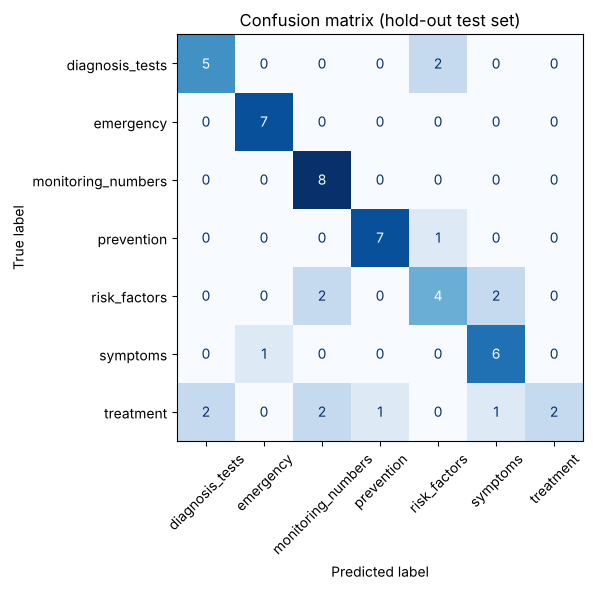

In [8]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

X_train, X_test, y_train, y_test = train_test_split(
    df["query"], df["intent"], test_size=0.3, stratify=df["intent"], random_state=42)

eval_model = Pipeline([("tfidf", make_vectorizer()), ("clf", LogisticRegression(C=20, max_iter=2000))])
eval_model.fit(X_train, y_train)
pred = eval_model.predict(X_test)

labels = sorted(df["intent"].unique())
acc = accuracy_score(y_test, pred)
p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")
print(f"Accuracy         : {acc:.3f}")
print(f"Macro precision  : {p:.3f}")
print(f"Macro recall     : {r:.3f}")
print(f"Macro F1-score   : {f:.3f}\n")
print(classification_report(y_test, pred, labels=labels, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels), display_labels=labels).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Confusion matrix (hold-out test set)")
plt.tight_layout()
plt.show()

In [9]:
# Harder test: differently worded queries that are NOT in the training corpus
paraphrase_set = [
    ("what are the early signals that my heart might be in trouble", "symptoms"),
    ("pain in the centre of my chest when I climb stairs that goes away on resting", "symptoms"),
    ("why do smokers get more cardiac illness", "risk_factors"),
    ("does having sugar problems make heart trouble more likely", "risk_factors"),
    ("which meals are friendly for my heart", "prevention"),
    ("ways to lower my odds of cardiac trouble", "prevention"),
    ("what does the doctor do to check how well my heart is pumping", "diagnosis_tests"),
    ("tests to see if my arteries are blocked", "diagnosis_tests"),
    ("what should my blood pressure be", "monitoring_numbers"),
    ("what counts as bad cholesterol numbers", "monitoring_numbers"),
    ("how do stents work for blocked arteries", "treatment"),
    ("what tablets do cardiologists prescribe after a heart attack", "treatment"),
    ("my mother has sudden crushing chest pain and is sweating a lot", "emergency"),
    ("he fell down and is not responding or breathing", "emergency"),
]
para_df = pd.DataFrame(paraphrase_set, columns=["query", "true intent"])

full_model = Pipeline([("tfidf", make_vectorizer()), ("clf", LogisticRegression(C=20, max_iter=2000))])
full_model.fit(df["query"], df["intent"])            # final model, trained on the whole corpus

proba = full_model.predict_proba(para_df["query"])
para_df["predicted"] = full_model.classes_[proba.argmax(axis=1)]
para_df["confidence"] = proba.max(axis=1).round(2)
para_df["correct"] = para_df["predicted"] == para_df["true intent"]
print("Accuracy on differently worded queries: %.3f" % para_df["correct"].mean())
para_df

Accuracy on differently worded queries: 0.929


,query,true intent,predicted,confidence,correct
0,what are the early signals that my heart might be in trouble,symptoms,symptoms,0.52,True
1,pain in the centre of my chest when I climb stairs that goes away on resting,symptoms,symptoms,0.59,True
2,why do smokers get more cardiac illness,risk_factors,risk_factors,0.32,True
3,does having sugar problems make heart trouble more likely,risk_factors,risk_factors,0.69,True
4,which meals are friendly for my heart,prevention,prevention,0.65,True
5,ways to lower my odds of cardiac trouble,prevention,treatment,0.45,False
6,what does the doctor do to check how well my heart is pumping,diagnosis_tests,diagnosis_tests,0.87,True
7,tests to see if my arteries are blocked,diagnosis_tests,diagnosis_tests,0.86,True
8,what should my blood pressure be,monitoring_numbers,monitoring_numbers,0.97,True
9,what counts as bad cholesterol numbers,monitoring_numbers,monitoring_numbers,0.84,True


**Reading the results:** with only 175 labelled queries and a 53-query hold-out set, every figure is a rough estimate (one query moves a class's recall by 12-25 points). Some intents overlap in meaning (for example *symptoms* vs *emergency*, or *treatment* vs *prevention*), so confusions between them are expected; check the confusion matrix and the *correct = False* rows above to see where the model is weakest. Collecting more real user queries is the most effective way to improve it.

### Choosing the low-confidence threshold from data
For every corpus query the model's probability is obtained from a fold that did **not** train on it (5-fold out-of-fold predictions). The table shows, for each candidate threshold, what share of queries the assistant would still answer (*coverage*) and how often those answers have the right intent (*accuracy when answering*). The threshold used by rule R5 is taken from this table.

In [10]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(Pipeline([("tfidf", make_vectorizer()), ("clf", LogisticRegression(C=20, max_iter=2000))]),
                        df["query"], df["intent"], cv=cv, method="predict_proba")
classes = np.array(sorted(df["intent"].unique()))
oof_pred, oof_conf = classes[oof.argmax(axis=1)], oof.max(axis=1)
oof_ok = oof_pred == df["intent"].values

rows = []
for t in [0.0, 0.2, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6]:
    answered = oof_conf >= t
    rows.append([t, round(answered.mean(), 2), round(oof_ok[answered].mean(), 2) if answered.any() else None])
thr_table = pd.DataFrame(rows, columns=["threshold", "coverage (answered)", "accuracy when answering"])
thr_table

,threshold,coverage (answered),accuracy when answering
0,0.00,1.00,0.77
1,0.20,1.00,0.77
2,0.30,0.94,0.80
3,0.35,0.91,0.81
4,0.40,0.83,0.82
5,0.45,0.78,0.84
6,0.50,0.73,0.85
7,0.60,0.61,0.90


## 7. Knowledge base (Requirement 7)
Several short, plain-language entries for every intent (23 in total). Retrieval first picks the intent, then finds the best-matching entry inside that intent.
This is general educational content; thresholds follow commonly used guidance (e.g. ACC/AHA blood-pressure categories) and a doctor may set different targets for an individual.

In [11]:
EMERGENCY_NUMBERS = ("Call your local emergency number NOW: 112 (India) - 108 for an ambulance in many Indian states - "
                     "911 (US) - 999 (UK).")

kb_entries = [
    # ---------------- symptoms
    ("symptoms", "Heart attack warning signs",
     "Common signs are chest pressure, tightness, squeezing or pain lasting more than a few minutes (or coming and going); discomfort spreading to "
     "the arm(s), shoulder, back, neck, jaw or upper belly; shortness of breath; cold sweat, nausea or light-headedness. Women, older adults and "
     "people with diabetes may have less typical symptoms such as unusual tiredness, nausea or back and jaw pain. A suspected heart attack is an emergency."),
    ("symptoms", "Angina (chest discomfort from the heart)",
     "Angina feels like pressure, heaviness or squeezing in the chest, often triggered by exertion, stress or cold weather, and it usually eases within "
     "a few minutes of rest. It happens when the heart muscle gets too little blood. New, worsening angina, or angina at rest, needs urgent medical review."),
    ("symptoms", "Heart failure symptoms",
     "Possible signs are breathlessness (especially on exertion or when lying flat), swelling of the ankles, legs or belly, constant tiredness, rapid "
     "weight gain from fluid, and a persistent cough or wheeze. These need a doctor's assessment; sudden severe breathlessness is an emergency."),
    ("symptoms", "Palpitations and irregular heartbeat",
     "Palpitations are the awareness of a fast, pounding, fluttering or skipped heartbeat. They are often harmless (caffeine, stress, lack of sleep) but "
     "see a doctor if they are frequent or last long, or come with dizziness, fainting, chest pain or breathlessness."),
    # ---------------- risk factors
    ("risk_factors", "Main risk factors you can change",
     "High blood pressure, high LDL cholesterol, smoking or tobacco use, diabetes, overweight or obesity, physical inactivity, an unhealthy diet, "
     "heavy alcohol use and long-term stress all raise the risk of heart disease. Controlling them lowers the risk."),
    ("risk_factors", "Risk factors you cannot change",
     "Age (risk rises as you get older), family history of early heart disease (father or brother before 55, mother or sister before 65), and "
     "ethnic background (South Asians tend to develop heart disease earlier) increase risk. Knowing them helps your doctor decide how closely to screen you."),
    ("risk_factors", "High blood pressure and the heart",
     "Persistently high blood pressure makes the heart work harder and damages artery walls. Over time it raises the risk of heart attack, heart "
     "failure and stroke. It often causes no symptoms, so regular checks matter."),
    ("risk_factors", "Diabetes, smoking and obesity",
     "Diabetes damages blood vessels and nerves and significantly raises the risk of heart disease. Smoking injures artery walls and promotes plaque "
     "build-up. Obesity raises blood pressure, cholesterol and diabetes risk, which in turn strain the heart."),
    # ---------------- prevention
    ("prevention", "Heart-healthy eating",
     "Eat plenty of vegetables, fruit, whole grains, pulses, nuts and fish; limit salt (the WHO suggests under 5 g of salt a day), saturated and trans "
     "fats, sugary drinks and processed food. Cooking at home with little oil helps."),
    ("prevention", "Exercise for heart health",
     "Adults are generally advised to do at least 150 minutes of moderate activity (such as brisk walking) per week, or 75 minutes of vigorous activity, "
     "plus muscle-strengthening on two days. Start slowly if you are new to exercise, and ask your doctor first if you already have heart disease."),
    ("prevention", "Quitting smoking and tobacco",
     "Heart risk begins to fall soon after stopping smoking and keeps falling over the following years. Counselling, support programmes and, when your "
     "doctor advises, nicotine replacement or other medicines can double your chances of quitting."),
    ("prevention", "Weight, sleep and stress",
     "Keeping a healthy weight, sleeping 7-9 hours, limiting alcohol and finding ways to manage stress (activity, relaxation, social support) all "
     "protect the heart."),
    # ---------------- diagnosis tests
    ("diagnosis_tests", "ECG (electrocardiogram)",
     "A quick, painless test that records the heart's electrical activity using stickers on the chest. It can show abnormal rhythms and signs of a "
     "heart attack or reduced blood supply to the heart."),
    ("diagnosis_tests", "Echocardiogram",
     "An ultrasound scan of the heart. It shows the heart's size, how well it pumps (ejection fraction) and how the valves work. It is used to "
     "check for heart failure and valve disease."),
    ("diagnosis_tests", "Stress test (treadmill test)",
     "An ECG is recorded while you walk on a treadmill, or after a medicine that mimics exercise. It shows whether the heart gets enough blood "
     "when it works harder."),
    ("diagnosis_tests", "Blood tests: lipid profile and troponin",
     "A lipid profile measures total cholesterol, LDL, HDL and triglycerides (some labs ask for fasting). A troponin test detects heart-muscle "
     "injury and is used in suspected heart attacks."),
    ("diagnosis_tests", "Angiography",
     "Coronary angiography (or CT angiography) uses contrast dye and X-rays to show whether the heart's arteries are narrowed or blocked. "
     "It helps decide on stents or bypass surgery."),
    # ---------------- monitoring numbers
    ("monitoring_numbers", "Blood pressure categories",
     "Commonly used adult categories (ACC/AHA): normal is below 120/80 mmHg; elevated is 120-129 over below 80; stage 1 hypertension is 130-139 or 80-89; "
     "stage 2 is 140/90 or higher. Above 180/120 is a hypertensive crisis. One reading does not make a diagnosis; your doctor looks at repeated readings."),
    ("monitoring_numbers", "Measuring blood pressure at home",
     "Rest seated for 5 minutes with your back supported, feet flat and the arm at heart level. Avoid caffeine, smoking and exercise for 30 minutes "
     "before. Take two readings one minute apart, morning and evening for a week, and note them down for your doctor. Use a validated upper-arm monitor."),
    ("monitoring_numbers", "Cholesterol numbers",
     "Total cholesterol under 200 mg/dL is considered desirable. For LDL ('bad' cholesterol) lower is better and the target depends on your overall "
     "risk, so ask your doctor. HDL ('good' cholesterol) is considered low below 40 mg/dL in men and 50 mg/dL in women. Triglycerides are normal below 150 mg/dL."),
    # ---------------- treatment
    ("treatment", "Common heart medicines",
     "Statins lower LDL cholesterol; beta-blockers slow the heart rate and lower blood pressure; ACE inhibitors or ARBs lower blood pressure and protect "
     "the heart; diuretics remove extra fluid; nitrates relieve angina; antiplatelets help prevent clots. Only a doctor should prescribe or change them."),
    ("treatment", "Angioplasty and stents, bypass surgery, pacemakers",
     "Angioplasty opens a blocked artery with a balloon and usually leaves a stent. Bypass surgery (CABG) reroutes blood around blocked arteries. "
     "A pacemaker corrects a heart rhythm that is too slow; an ICD treats dangerous fast rhythms."),
    ("treatment", "Cardiac rehabilitation",
     "A supervised programme of exercise, education and counselling after a heart attack, heart surgery or with heart failure. It improves recovery "
     "and lowers the chance of further heart problems."),
    ("treatment", "Taking heart medicines safely",
     "Take heart medicines exactly as prescribed. Do not stop, skip or change a dose on your own, even if you feel well, because that can be dangerous. "
     "Ask your doctor or pharmacist what to do about a missed dose or side effects."),
    # ---------------- emergency
    ("emergency", "What to do in a suspected heart attack",
     EMERGENCY_NUMBERS + " Stop all activity and sit down, loosen tight clothing and stay calm. Do not drive yourself. Do not wait to see if the pain "
     "passes. The emergency dispatcher may advise chewing an aspirin if you are not allergic - follow their instructions."),
    ("emergency", "If someone collapses",
     EMERGENCY_NUMBERS + " If the person does not respond and is not breathing normally, start CPR: push hard and fast in the centre of the chest "
     "(about 100-120 pushes a minute) and use an AED if one is available, until help arrives."),
]
# extra search words per entry (used only for retrieval, never shown to the user)
KB_KEYWORDS = {
    "Heart attack warning signs": "heart attack myocardial infarction symptom sign warning chest pain women",
    "Angina (chest discomfort from the heart)": "angina chest pain pressure exertion",
    "Heart failure symptoms": "heart failure swelling swollen breathless tired fluid",
    "Palpitations and irregular heartbeat": "palpitation flutter skip irregular heartbeat racing",
    "Main risk factors you can change": "risk factor cause modifiable smoking cholesterol blood pressure obesity inactivity alcohol",
    "Risk factors you cannot change": "age family history genetic hereditary inherited south asian young",
    "High blood pressure and the heart": "high blood pressure hypertension risk dangerous",
    "Diabetes, smoking and obesity": "diabetes diabetic sugar smoking tobacco obesity overweight weight risk",
    "Heart-healthy eating": "diet food eat meal salt vegetable fat oil",
    "Exercise for heart health": "exercise walk walking activity cardio jogging workout minutes",
    "Quitting smoking and tobacco": "quit stop smoking tobacco cigarette",
    "Weight, sleep and stress": "weight sleep stress alcohol relax yoga meditation",
    "ECG (electrocardiogram)": "ecg ekg electrocardiogram rhythm electrical",
    "Echocardiogram": "echo echocardiogram 2d ultrasound pumping ejection fraction valve",
    "Stress test (treadmill test)": "stress test treadmill tmt exercise test",
    "Blood tests: lipid profile and troponin": "blood test lipid profile troponin cholesterol",
    "Angiography": "angiography angiogram ct blocked artery blockage dye",
    "Blood pressure categories": "blood pressure normal high low category stage hypertension reading range systolic diastolic",
    "Measuring blood pressure at home": "measure blood pressure home monitor check often",
    "Cholesterol numbers": "cholesterol ldl hdl triglyceride level number lipid total",
    "Common heart medicines": "medicine medication tablet drug statin beta blocker ace inhibitor aspirin blood thinner",
    "Angioplasty and stents, bypass surgery, pacemakers": "angioplasty stent bypass cabg surgery pacemaker icd defibrillator transplant valve",
    "Cardiac rehabilitation": "rehabilitation rehab recovery programme",
    "Taking heart medicines safely": "medicine safety dose stop missed side effect",
    "What to do in a suspected heart attack": "heart attack chest pain emergency ambulance call",
    "If someone collapses": "collapse faint unconscious cpr aed breathing pulse",
}
kb = pd.DataFrame(kb_entries, columns=["intent", "topic", "content"])
kb["keywords"] = kb["topic"].map(KB_KEYWORDS)
assert kb["keywords"].notna().all()
print("Knowledge-base entries:", len(kb))
print(kb.groupby("intent").size().to_string())
kb[["intent", "topic"]]

Knowledge-base entries: 26
intent
diagnosis_tests       5
emergency             2
monitoring_numbers    3
prevention            4
risk_factors          4
symptoms              4
treatment             4


,intent,topic
0,symptoms,Heart attack warning signs
1,symptoms,Angina (chest discomfort from the heart)
2,symptoms,Heart failure symptoms
3,symptoms,Palpitations and irregular heartbeat
4,risk_factors,Main risk factors you can change
5,risk_factors,Risk factors you cannot change
6,risk_factors,High blood pressure and the heart
7,risk_factors,"Diabetes, smoking and obesity"
8,prevention,Heart-healthy eating
9,prevention,Exercise for heart health


## 8. Reasoning rules (Requirement 8)
Eight rules sit around the classifier. Safety rules run **before** it, so they cannot be overridden by a classification mistake.

| # | Rule | When it fires | Action |
|---|------|---------------|--------|
| R1 | **Emergency escalation** | emergency symptoms + an urgency cue, or an unmistakable emergency phrase | Show emergency instructions immediately |
| R2 | **Small-talk** | greeting / thanks / goodbye | Short friendly reply |
| R3 | **Unsupported query** | non-heart health topic, or no overlap with anything the assistant knows | Say it is outside scope, suggest a professional |
| R4 | **BP-reading interpreter** | a reading such as `150/95` appears in the query | Classify the reading; escalate a crisis-level reading |
| R5 | **Low confidence** | classifier's top probability below the threshold | Ask the user to rephrase, show the two closest topics |
| R6 | **Medication safety** | asks about stopping, starting or changing a dose | Refuse to advise, refer to the doctor / pharmacist |
| R7 | **Personal-diagnosis guard** | "do I have…", "diagnose me" | Explain it cannot diagnose, give the relevant general information |
| R8 | **Disclaimer + concept reasoning** | every informational answer | Append the disclaimer and related facts from the concept graph |

## 9. The integrated assistant (Requirement 9)
NLP preprocessing, intent classification, rule-based reasoning, knowledge retrieval and response generation in one class.

In [12]:
from sklearn.metrics.pairwise import cosine_similarity

CONFIDENCE_THRESHOLD = 0.45     # R5: chosen from the coverage/accuracy table in section 6 (>=75 % coverage, ~84 % accuracy when answering)
MARGIN = 0.08                   # R5: top-2 probabilities closer than this = ambiguous
OOD_SIMILARITY = 0.12           # R3: below this the query shares almost nothing with the corpus
DISCLAIMER = "Note: this is general educational information, not a diagnosis. Please consult a doctor for advice about your own health."

INTENT_TITLES = {
    "symptoms": "Symptoms & warning signs", "risk_factors": "Risk factors", "prevention": "Prevention & lifestyle",
    "diagnosis_tests": "Heart tests & diagnosis", "monitoring_numbers": "Blood pressure & cholesterol numbers",
    "treatment": "Treatment & care", "emergency": "Emergency care",
}

# ---- vocabulary used by the rules ------------------------------------------------
HEART_TERMS = {"heart", "cardiac", "cardio", "cardiologist", "chest", "blood", "pressure", "bp", "cholesterol", "ldl", "hdl",
               "triglyceride", "artery", "coronary", "angina", "ecg", "echocardiogram", "statin", "pacemaker", "angioplasty",
               "bypass", "palpitation", "hypertension", "attack", "stent", "arrhythmia", "heartbeat", "pulse", "cpr", "aspirin"}

OTHER_TOPICS = {"migraine", "headache", "fever", "cold", "flu", "asthma", "cancer", "tumor", "skin", "acne", "rash", "pregnancy",
                "pregnant", "kidney", "liver", "thyroid", "arthritis", "depression", "anxiety", "dental", "tooth", "eye",
                "vision", "stomach", "ulcer", "allergy", "covid", "malaria", "dengue", "fracture", "hair", "diabetes", "sugar"}

EMERGENCY_HARD = [r"not breathing", r"\bunconscious\b", r"\bunresponsive\b", r"not responding", r"\bcollapsed\b", r"passed out",
                  r"stopped breathing", r"can(?:'|no)?t breathe", r"cannot breathe", r"crushing", r"call (?:an )?ambulance",
                  r"fell down and"]
EMERGENCY_SYMPTOM = [r"chest pain", r"chest tightness", r"chest pressure", r"pain in (?:my |the )?chest", r"heart attack",
                     r"cardiac arrest", r"severe breathless", r"can't breathe", r"short(?:ness)? of breath", r"pain (?:in|down) (?:my |the )?(?:left )?arm",
                     r"jaw pain", r"cold sweat", r"sweating"]
URGENCY_CUES = [r"right now", r"\bnow\b", r"\bsudden", r"\bsevere", r"\bintense", r"\bi(?:'m| am) having", r"\bhaving (?:a |an )?(?:severe |sudden )?(?:chest|heart)",
                r"\b(?:he|she|someone|my \w+) (?:is|has) (?:having|got)", r"\bi think i(?:'m| am| have)", r"\bspreading", r"\bis sweating", r"\bcurrently\b"]
INFO_FRAMES = [r"^\s*(?:what|which|how|why|when|is|are|do|does)\b.*\b(?:symptom|sign|cause|risk|prevent|test|diagnos|treat)"]

SMALL_TALK = {
    "greeting": (r"^\s*(?:hi|hello|hey|good (?:morning|afternoon|evening)|namaste)\b[\s!.]*$",
                 "Hello! I'm the Heart Health Information Assistant. Ask me about heart-attack symptoms, risk factors, prevention, "
                 "tests, blood pressure and cholesterol numbers, or treatments."),
    "thanks":   (r"^\s*(?:thanks|thank you|thx|ok thanks)\b[\s!.]*$", "You're welcome! Take care of your heart. Ask me anything else about heart health."),
    "bye":      (r"^\s*(?:bye|goodbye|see you|exit|quit)\b[\s!.]*$", "Goodbye, stay heart-healthy! If you ever feel severe chest pain, call emergency services immediately."),
}

MED_SAFETY = r"\b(?:stop|quit|skip|miss(?:ed)?|increase|decrease|reduce|double|dose|dosage|how (?:much|many) (?:mg|tablet|pill)|start taking|can i take|should i take|change my (?:medicine|medication|tablet))\b"
DIAG_REQUEST = r"\b(?:do i have|am i having heart (?:disease|problem)|diagnose me|what is wrong with me|is it a heart (?:problem|attack) for me)\b"
BP_READING = re.compile(r"\b(\d{2,3})\s*/\s*(\d{2,3})\b")
RED_FLAGS = r"chest pain|breathless|short(?:ness)? of breath|weakness|vision|confus|numb|faint|severe headache"

# ---- concept lexicon for the reasoning step -----------------------------------------
CONCEPT_WORDS = {
    "Smoking": {"smoking", "smoke", "smoker", "tobacco", "cigarette"},
    "High Cholesterol": {"cholesterol", "ldl", "lipid", "triglyceride"},
    "Hypertension": {"hypertension", "bp", "pressure"},
    "Diabetes": {"diabetes", "diabetic", "sugar"},
    "Obesity": {"obesity", "obese", "overweight", "weight"},
    "Atherosclerosis": {"atherosclerosis", "plaque", "blockage", "blocked"},
    "Coronary Artery Disease": {"coronary", "artery"},
    "Angina": {"angina"},
    "Heart Attack": {"attack", "infarction"},
    "Heart Failure": {"failure"},
    "Arrhythmia": {"arrhythmia", "palpitation", "irregular", "flutter", "skip"},
    "ECG": {"ecg", "ekg", "electrocardiogram"},
    "Statins": {"statin", "statins"},
    "Exercise": {"exercise", "walk", "walking", "workout", "activity"},
    "Healthy Diet": {"diet", "food", "salt", "meal", "eat", "eating"},
}

SYMPTOM_WORDS = {"pain", "breath", "breathless", "breathlessness", "breathe", "dizzy", "dizziness", "faint", "fainting", "palpitation",
                 "swelling", "swollen", "swell", "tired", "tiredness", "fatigue", "sweat", "nausea", "tight", "tightness", "squeeze",
                 "jaw", "arm", "pulse", "collapse", "unconscious", "ambulance", "holter", "troponin", "echo", "tmt", "icd",
                 "defibrillator", "aed", "cabg", "lipid", "triglyceride", "atherosclerosis", "plaque"}
DOMAIN_VOCAB = HEART_TERMS | SYMPTOM_WORDS | set().union(*CONCEPT_WORDS.values())

class HeartHealthAssistant:
    def __init__(self, model, kb, relationships, threshold=CONFIDENCE_THRESHOLD):
        self.model, self.kb, self.relationships, self.threshold = model, kb, relationships, threshold
        # TF-IDF index of the knowledge base (used for retrieval inside the predicted intent)
        kb_text = (kb["topic"] + " " + kb["keywords"] + " ") * 2 + kb["content"]   # title and search words count twice
        self.kb_vec = make_word_vectorizer().fit(kb_text)
        self.kb_matrix = self.kb_vec.transform(kb_text)
        # TF-IDF index of the training queries (used to spot out-of-domain queries)
        self.q_vec = make_word_vectorizer().fit(df["query"])
        self.q_matrix = self.q_vec.transform(df["query"])
        self.log = []

    # ---------------- helpers
    def _matches(self, patterns, text):
        return any(re.search(p, text) for p in patterns)

    def is_emergency(self, text):                       # R1
        t = text.lower()
        if self._matches(EMERGENCY_HARD, t):
            return True
        return self._matches(EMERGENCY_SYMPTOM, t) and self._matches(URGENCY_CUES, t)

    def emergency_text(self, low):
        entry = self.kb[self.kb["intent"] == "emergency"]
        collapse = re.search(r"collaps|unconscious|unrespons|not (?:breathing|responding)|stopped breathing|fell down|faint|cpr", low)
        pick = entry.iloc[1] if collapse else entry.iloc[0]
        return ("🚨 THIS MAY BE A MEDICAL EMERGENCY.\n" + pick["content"] +
                "\nDo not rely on this chat. Get professional help right now.")

    def concepts_in(self, lemmas):
        return [c for c, words in CONCEPT_WORDS.items() if words & set(lemmas)]

    def related_facts(self, lemmas, limit=3):           # reasoning over the concept graph
        found = self.concepts_in(lemmas)
        facts = [f"{a} {r} {b}" for a, r, b in self.relationships if a in found or b in found]
        return facts[:limit]

    def retrieve(self, query, intent):                  # knowledge retrieval
        idx = self.kb.index[self.kb["intent"] == intent].tolist()
        sims = cosine_similarity(self.kb_vec.transform([query]), self.kb_matrix[idx]).ravel()
        order = sims.argsort()[::-1]
        best = self.kb.loc[idx[order[0]]]
        others = [self.kb.loc[idx[i], "topic"] for i in order[1:3]]
        return best, round(float(sims[order[0]]), 2), others

    @staticmethod
    def classify_bp(sys_, dia):
        if sys_ > 180 or dia > 120:
            return "hypertensive crisis range", True
        if sys_ >= 140 or dia >= 90:
            return "stage 2 hypertension range", False
        if sys_ >= 130 or dia >= 80:
            return "stage 1 hypertension range", False
        if sys_ >= 120:
            return "elevated range", False
        if sys_ < 90 or dia < 60:
            return "low range", False
        return "normal range", False

    # ---------------- main entry point
    def respond(self, query):
        q = query.strip()
        result = {"query": q, "intent": None, "confidence": None, "rule": None, "response": ""}
        low = q.lower()

        if not q:
            result.update(rule="empty input", response="Please type a question about heart health.")
            return self._finish(result)

        # R2 small talk
        for kind, (pattern, reply) in SMALL_TALK.items():
            if re.match(pattern, low):
                result.update(rule=f"R2 small-talk ({kind})", response=reply)
                return self._finish(result)

        lemmas = preprocess(q)

        # R1 emergency escalation (before anything else)
        if self.is_emergency(q):
            result.update(intent="emergency", confidence=1.0, rule="R1 emergency escalation",
                          response=self.emergency_text(low))
            return self._finish(result)

        # R4 blood-pressure reading
        bp_note = ""
        m = BP_READING.search(q)
        if m and 70 <= int(m.group(1)) <= 260 and 40 <= int(m.group(2)) <= 150:
            s, d = int(m.group(1)), int(m.group(2))
            label, crisis = self.classify_bp(s, d)
            bp_note = f"A reading of {s}/{d} mmHg falls in the {label} (ACC/AHA categories). "
            if crisis:
                if re.search(RED_FLAGS, low):
                    result.update(intent="emergency", confidence=1.0, rule="R4 BP crisis + red-flag symptom -> R1",
                                  response="🚨 A reading this high together with these symptoms may be an emergency.\n" + EMERGENCY_NUMBERS)
                    return self._finish(result)
                result.update(intent="monitoring_numbers", confidence=1.0, rule="R4 BP reading (crisis range)",
                              response=bp_note + "One reading does not make a diagnosis. Rest for 5 minutes and measure again. If it is still above 180/120, contact a doctor immediately; "
                                       "if you have chest pain, breathlessness, weakness, vision change or confusion, call emergency services.\n" + DISCLAIMER)
                return self._finish(result)

        # R3 unsupported query
        has_heart = bool(HEART_TERMS & set(lemmas))
        if (OTHER_TOPICS & set(lemmas)) and not has_heart:
            result.update(rule="R3 unsupported (other health topic)",
                          response="That sounds like a health question outside heart health, which is all I can help with. "
                                   "Please ask a doctor or pharmacist about it.\nI can help with heart-attack symptoms, risk factors, prevention, "
                                   "tests, blood pressure/cholesterol numbers and treatments.")
            return self._finish(result)
        sim = cosine_similarity(self.q_vec.transform([q]), self.q_matrix).max()
        if sim < OOD_SIMILARITY and not has_heart and len(lemmas) >= 3:
            result.update(rule=f"R3 unsupported (no overlap, similarity {sim:.2f})",
                          response="I'm not able to help with that. I only answer questions about heart health "
                                   "(symptoms, risk factors, prevention, tests, blood pressure and cholesterol, treatments, emergencies).")
            return self._finish(result)

        # intent classification
        proba = self.model.predict_proba([q])[0]
        order = proba.argsort()[::-1]
        intent, conf = self.model.classes_[order[0]], float(proba[order[0]])
        second = self.model.classes_[order[1]]
        result.update(intent=intent, confidence=round(conf, 2))

        # R1 (second trigger): the classifier itself says "emergency"
        if intent == "emergency" and conf >= self.threshold:
            result.update(rule="R1 emergency escalation (classifier)", response=self.emergency_text(low))
            return self._finish(result)

        # R5 low confidence: no heart vocabulary, almost no usable words, weak top probability, or a near-tie between intents
        margin = float(proba[order[0]] - proba[order[1]])
        reason = None
        if not (DOMAIN_VOCAB & set(lemmas)) and not bp_note:
            reason = "I couldn't tell what you want to know about heart health"
        elif len(lemmas) < 2 and not bp_note:
            reason = "your question is very short"
        elif conf < self.threshold and not bp_note:
            reason = f"my confidence is only {conf:.0%}"
        elif margin < MARGIN and not bp_note:
            reason = "two topics seem equally likely"
        if reason:
            result.update(rule="R5 low confidence",
                          response=f"I'm not sure I understood ({reason}). Could you rephrase or be more specific?\n"
                                   f"For example, ask about symptoms, risk factors, prevention, tests, blood pressure or cholesterol numbers, or treatments. "
                                   f"My closest guesses were '{INTENT_TITLES[intent]}' and '{INTENT_TITLES[second]}'.")
            return self._finish(result)

        # R6 medication safety
        if re.search(MED_SAFETY, low) and (intent == "treatment" or re.search(r"medic|tablet|pill|drug|statin|aspirin|blocker", low)):
            result.update(intent="treatment", rule="R6 medication safety",
                          response="I can't advise on starting, stopping, skipping or changing the dose of any medicine. "
                                   "Please talk to your doctor or pharmacist before making any change. Stopping heart medicines suddenly can be dangerous.\n" + DISCLAIMER)
            return self._finish(result)

        # R7 personal diagnosis guard
        guard = ""
        if re.search(DIAG_REQUEST, low):
            guard = "I can't diagnose you. A doctor needs to examine you and may order tests. Meanwhile, here is general information:\n"
            result["rule"] = "R7 personal-diagnosis guard"

        # knowledge retrieval + concept reasoning
        entry, sim_kb, others = self.retrieve(q, intent)
        facts = self.related_facts(lemmas)
        text = guard + bp_note + f"[{entry['topic']}] {entry['content']}"
        if facts:
            text += "\nRelated: " + "; ".join(facts) + "."
        if others:
            text += "\nYou may also ask about: " + ", ".join(others) + "."
        text += "\n" + DISCLAIMER
        result["rule"] = result["rule"] or ("R4 BP reading + retrieval" if bp_note else "classifier + knowledge retrieval (R8)")
        result["response"] = text
        return self._finish(result)

    def _finish(self, result):
        self.log.append(result)
        return result

assistant = HeartHealthAssistant(full_model, kb, relationships)

def show(result):
    conf = "-" if result["confidence"] is None else f"{result['confidence']:.2f}"
    print(f"USER      : {result['query']}")
    print(f"INTENT    : {result['intent']}   | confidence: {conf}   | rule: {result['rule']}")
    print("ASSISTANT :", result["response"].replace("\n", "\n            "))
    print("-" * 100)

show(assistant.respond("What are the symptoms of a heart attack?"))

USER      : What are the symptoms of a heart attack?
INTENT    : symptoms   | confidence: 0.97   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [Heart attack warning signs] Common signs are chest pressure, tightness, squeezing or pain lasting more than a few minutes (or coming and going); discomfort spreading to the arm(s), shoulder, back, neck, jaw or upper belly; shortness of breath; cold sweat, nausea or light-headedness. Women, older adults and people with diabetes may have less typical symptoms such as unusual tiredness, nausea or back and jaw pain. A suspected heart attack is an emergency.
            Related: Coronary Artery Disease can lead to Heart Attack; Hypertension increases risk of Heart Attack; Heart Attack can cause Heart Failure.
            You may also ask about: Heart failure symptoms, Angina (chest discomfort from the heart).
            Note: this is general educational information, not a diagnosis. Please consult a doctor for advice about your own heal

### Checking the retrieval step
Ten queries with the knowledge-base entry that *should* be returned. Only the retrieval step is tested here (the intent is given, not predicted).

In [13]:
retrieval_tests = [
    ("what are the symptoms of a heart attack", "symptoms", "Heart attack warning signs"),
    ("how does angina feel", "symptoms", "Angina (chest discomfort from the heart)"),
    ("is heart disease hereditary", "risk_factors", "Risk factors you cannot change"),
    ("which foods are good for the heart", "prevention", "Heart-healthy eating"),
    ("what does an ECG show", "diagnosis_tests", "ECG (electrocardiogram)"),
    ("what is a 2D echo", "diagnosis_tests", "Echocardiogram"),
    ("how do I measure blood pressure at home", "monitoring_numbers", "Measuring blood pressure at home"),
    ("what is a healthy HDL level", "monitoring_numbers", "Cholesterol numbers"),
    ("what is a stent", "treatment", "Angioplasty and stents, bypass surgery, pacemakers"),
    ("how do I give CPR to someone", "emergency", "If someone collapses"),
]
rows = []
for q, intent, expected in retrieval_tests:
    got, score, _ = assistant.retrieve(q, intent)
    rows.append([q, expected, got["topic"], got["topic"] == expected])
ret = pd.DataFrame(rows, columns=["query", "expected entry", "retrieved entry", "hit"])
print("Retrieval hit rate: %.0f %%" % (100 * ret["hit"].mean()))
ret

Retrieval hit rate: 100 %


,query,expected entry,retrieved entry,hit
0,what are the symptoms of a heart attack,Heart attack warning signs,Heart attack warning signs,True
1,how does angina feel,Angina (chest discomfort from the heart),Angina (chest discomfort from the heart),True
2,is heart disease hereditary,Risk factors you cannot change,Risk factors you cannot change,True
3,which foods are good for the heart,Heart-healthy eating,Heart-healthy eating,True
4,what does an ECG show,ECG (electrocardiogram),ECG (electrocardiogram),True
5,what is a 2D echo,Echocardiogram,Echocardiogram,True
6,how do I measure blood pressure at home,Measuring blood pressure at home,Measuring blood pressure at home,True
7,what is a healthy HDL level,Cholesterol numbers,Cholesterol numbers,True
8,what is a stent,"Angioplasty and stents, bypass surgery, pacemakers","Angioplasty and stents, bypass surgery, pacemakers",True
9,how do I give CPR to someone,If someone collapses,If someone collapses,True


## 10. Interactive Colab interface (Requirement 10)
A text box plus **Send** / **Clear** buttons (built with `ipywidgets`, which Colab supports). Type a question and press Enter or click Send; the conversation stays on screen so many queries can be asked one after another.
Run the cell below and use the box that appears under it.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML
import html

def build_ui(assistant):
    box = widgets.Text(placeholder="Ask a heart-health question and press Enter...", layout=widgets.Layout(width="75%"))
    send = widgets.Button(description="Send", button_style="primary", icon="paper-plane")
    clear = widgets.Button(description="Clear", icon="trash")
    chat = widgets.Output(layout=widgets.Layout(border="1px solid #ccc", padding="8px", max_height="420px", overflow_y="auto"))

    def add(role, text, color):
        with chat:
            display(HTML(f"<div style='margin:4px 0;padding:6px 10px;border-radius:8px;background:{color};white-space:pre-wrap'>"
                         f"<b>{role}:</b> {html.escape(text)}</div>"))

    def handle(_=None):
        q = box.value.strip()
        if not q:
            return
        res = assistant.respond(q)
        emergency = res["rule"] and res["rule"].startswith(("R1", "R4 BP crisis"))
        add("You", q, "#eef3ff")
        meta = f"[intent: {res['intent']} | confidence: {res['confidence']} | rule: {res['rule']}]"
        add("Assistant", res["response"] + "\n" + meta, "#ffe3e3" if emergency else "#eaf7ea")
        box.value = ""

    send.on_click(handle)
    box.on_submit(handle)
    clear.on_click(lambda _: chat.clear_output())
    add("Assistant", "Hello! Ask me about heart-attack symptoms, risk factors, prevention, tests, blood pressure and cholesterol, or treatments.", "#eaf7ea")
    return widgets.VBox([widgets.HBox([box, send, clear]), chat])

ui = build_ui(assistant)
display(ui)

## Testing the assistant
Five kinds of test, as required: **(1)** one query for every intent, **(2)** a differently worded query, **(3)** an unsupported healthcare query, **(4)** a low-confidence query and **(5)** emergency-related queries.

### Test 1 — one query for each intent

In [14]:
test1 = [
    "What are the signs of a heart attack?",                          # symptoms
    "Does smoking raise the chance of heart disease?",                # risk_factors
    "What foods should I eat to protect my heart?",                   # prevention
    "What does an ECG show?",                                         # diagnosis_tests
    "What is a normal cholesterol level?",                            # monitoring_numbers
    "What is cardiac rehabilitation?",                                # treatment
    "What should I do if someone has a heart attack?",                # emergency (information)
]
for q in test1:
    show(assistant.respond(q))

USER      : What are the signs of a heart attack?
INTENT    : symptoms   | confidence: 0.96   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [Heart attack warning signs] Common signs are chest pressure, tightness, squeezing or pain lasting more than a few minutes (or coming and going); discomfort spreading to the arm(s), shoulder, back, neck, jaw or upper belly; shortness of breath; cold sweat, nausea or light-headedness. Women, older adults and people with diabetes may have less typical symptoms such as unusual tiredness, nausea or back and jaw pain. A suspected heart attack is an emergency.
            Related: Coronary Artery Disease can lead to Heart Attack; Hypertension increases risk of Heart Attack; Heart Attack can cause Heart Failure.
            You may also ask about: Heart failure symptoms, Angina (chest discomfort from the heart).
            Note: this is general educational information, not a diagnosis. Please consult a doctor for advice about your own health.

USER      : What does an ECG show?
INTENT    : diagnosis_tests   | confidence: 0.81   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [ECG (electrocardiogram)] A quick, painless test that records the heart's electrical activity using stickers on the chest. It can show abnormal rhythms and signs of a heart attack or reduced blood supply to the heart.
            Related: ECG helps detect Arrhythmia; ECG helps diagnose Heart Attack.
            You may also ask about: Stress test (treadmill test), Angiography.
            Note: this is general educational information, not a diagnosis. Please consult a doctor for advice about your own health.
----------------------------------------------------------------------------------------------------
USER      : What is a normal cholesterol level?
INTENT    : monitoring_numbers   | confidence: 0.97   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [Cholesterol numbers] Total cholesterol under 200 mg/dL is considered desirable. 

### Test 2 — differently worded queries (not in the training corpus)

In [15]:
test2 = [
    "Which meals are friendly for my heart?",
    "What does the doctor do to check how well my heart is pumping?",
    "How do stents help blocked arteries?",
]
for q in test2:
    show(assistant.respond(q))

USER      : Which meals are friendly for my heart?
INTENT    : prevention   | confidence: 0.63   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [Heart-healthy eating] Eat plenty of vegetables, fruit, whole grains, pulses, nuts and fish; limit salt (the WHO suggests under 5 g of salt a day), saturated and trans fats, sugary drinks and processed food. Cooking at home with little oil helps.
            Related: Healthy Diet helps lower High Cholesterol.
            You may also ask about: Exercise for heart health, Quitting smoking and tobacco.
            Note: this is general educational information, not a diagnosis. Please consult a doctor for advice about your own health.
----------------------------------------------------------------------------------------------------
USER      : What does the doctor do to check how well my heart is pumping?
INTENT    : diagnosis_tests   | confidence: 0.88   | rule: classifier + knowledge retrieval (R8)
ASSISTANT : [Echocardiogram] An ul

### Test 3 — unsupported healthcare query (outside heart health)

In [16]:
for q in ["How can I get rid of my migraine?", "What is the best way to treat acne?", "Who won the cricket match yesterday?"]:
    show(assistant.respond(q))

USER      : How can I get rid of my migraine?
INTENT    : None   | confidence: -   | rule: R3 unsupported (other health topic)
ASSISTANT : That sounds like a health question outside heart health, which is all I can help with. Please ask a doctor or pharmacist about it.
            I can help with heart-attack symptoms, risk factors, prevention, tests, blood pressure/cholesterol numbers and treatments.
----------------------------------------------------------------------------------------------------
USER      : What is the best way to treat acne?
INTENT    : None   | confidence: -   | rule: R3 unsupported (other health topic)
ASSISTANT : That sounds like a health question outside heart health, which is all I can help with. Please ask a doctor or pharmacist about it.
            I can help with heart-attack symptoms, risk factors, prevention, tests, blood pressure/cholesterol numbers and treatments.
---------------------------------------------------------------------------------------

### Test 4 — low-confidence query

In [17]:
for q in ["heart", "Tell me something about my health", "I feel a bit off today", "Is it serious?"]:
    show(assistant.respond(q))

USER      : heart
INTENT    : prevention   | confidence: 0.76   | rule: R5 low confidence
ASSISTANT : I'm not sure I understood (your question is very short). Could you rephrase or be more specific?
            For example, ask about symptoms, risk factors, prevention, tests, blood pressure or cholesterol numbers, or treatments. My closest guesses were 'Prevention & lifestyle' and 'Risk factors'.
----------------------------------------------------------------------------------------------------
USER      : Tell me something about my health
INTENT    : prevention   | confidence: 0.52   | rule: R5 low confidence
ASSISTANT : I'm not sure I understood (I couldn't tell what you want to know about heart health). Could you rephrase or be more specific?
            For example, ask about symptoms, risk factors, prevention, tests, blood pressure or cholesterol numbers, or treatments. My closest guesses were 'Prevention & lifestyle' and 'Emergency care'.
----------------------------------------

### Test 5 — emergency-related queries

In [18]:
for q in ["I am having crushing chest pain and my left arm hurts right now",
          "My father just collapsed and is not breathing",
          "My blood pressure reading is 190/125 and I have a severe headache and weakness"]:
    show(assistant.respond(q))

USER      : I am having crushing chest pain and my left arm hurts right now
INTENT    : emergency   | confidence: 1.00   | rule: R1 emergency escalation
ASSISTANT : 🚨 THIS MAY BE A MEDICAL EMERGENCY.
            Call your local emergency number NOW: 112 (India) - 108 for an ambulance in many Indian states - 911 (US) - 999 (UK). Stop all activity and sit down, loosen tight clothing and stay calm. Do not drive yourself. Do not wait to see if the pain passes. The emergency dispatcher may advise chewing an aspirin if you are not allergic - follow their instructions.
            Do not rely on this chat. Get professional help right now.
----------------------------------------------------------------------------------------------------
USER      : My father just collapsed and is not breathing
INTENT    : emergency   | confidence: 1.00   | rule: R1 emergency escalation
ASSISTANT : 🚨 THIS MAY BE A MEDICAL EMERGENCY.
            Call your local emergency number NOW: 112 (India) - 108 for an am

### Extra checks — the other rules (R2, R4, R6, R7)

In [19]:
for q in ["Hello", "Is 150/95 blood pressure high?", "My BP is 185/121 what should I do",
          "Can I stop taking my statin because I feel fine?", "Do I have heart disease?", "Thanks"]:
    show(assistant.respond(q))

USER      : Hello
INTENT    : None   | confidence: -   | rule: R2 small-talk (greeting)
ASSISTANT : Hello! I'm the Heart Health Information Assistant. Ask me about heart-attack symptoms, risk factors, prevention, tests, blood pressure and cholesterol numbers, or treatments.
----------------------------------------------------------------------------------------------------
USER      : Is 150/95 blood pressure high?
INTENT    : monitoring_numbers   | confidence: 0.98   | rule: R4 BP reading + retrieval
ASSISTANT : A reading of 150/95 mmHg falls in the stage 2 hypertension range (ACC/AHA categories). [Blood pressure categories] Commonly used adult categories (ACC/AHA): normal is below 120/80 mmHg; elevated is 120-129 over below 80; stage 1 hypertension is 130-139 or 80-89; stage 2 is 140/90 or higher. Above 180/120 is a hypertensive crisis. One reading does not make a diagnosis; your doctor looks at repeated readings.
            Related: Hypertension increases risk of Heart Attack; Hype

In [20]:
# Rule summary: which rule handled each query so far
log = pd.DataFrame(assistant.log)
log["rule group"] = log["rule"].str.extract(r"^(R\d)")[0].fillna("classifier")
print(log["rule group"].value_counts().to_string())

rule group
classifier    10
R5             4
R1             3
R3             3
R4             3
R2             2
R6             1
R7             1


## Limitations and notes
- The corpus is small (175 queries), so accuracy figures are indicative only; a real system needs hundreds of labelled queries from real users.
- The emergency rule is deliberately **conservative**: it may escalate a borderline informational question ("how do I know if I'm having a heart attack?") rather than risk missing a real emergency.
- The knowledge base is short, plain-language and general. It should be reviewed by a clinician before any real-world use.
- The assistant never gives medicine doses, never diagnoses, and always points the user to a doctor or emergency services where appropriate.